<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/DW_rigid_strain_SAW_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

minimizing...
running...


100%|██████████| 1001/1001 [00:44<00:00, 22.38it/s]


done!


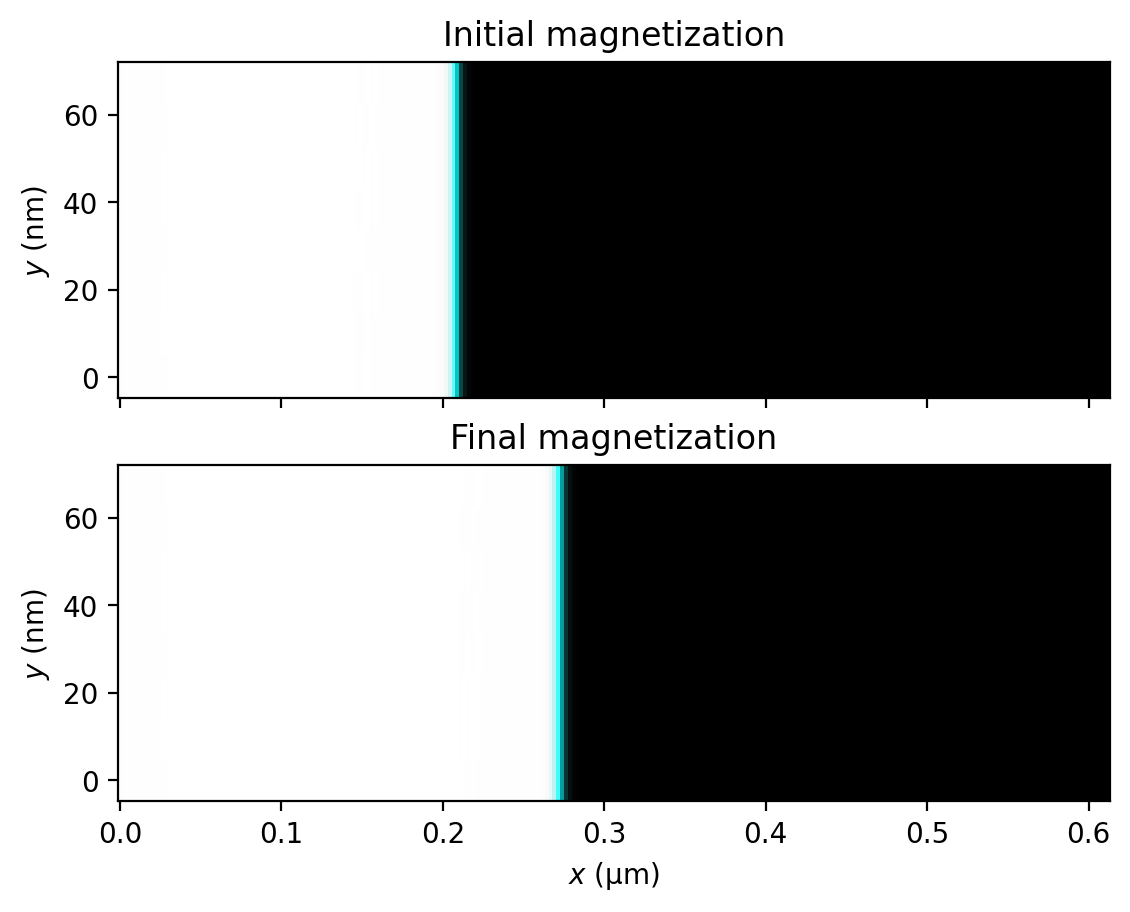

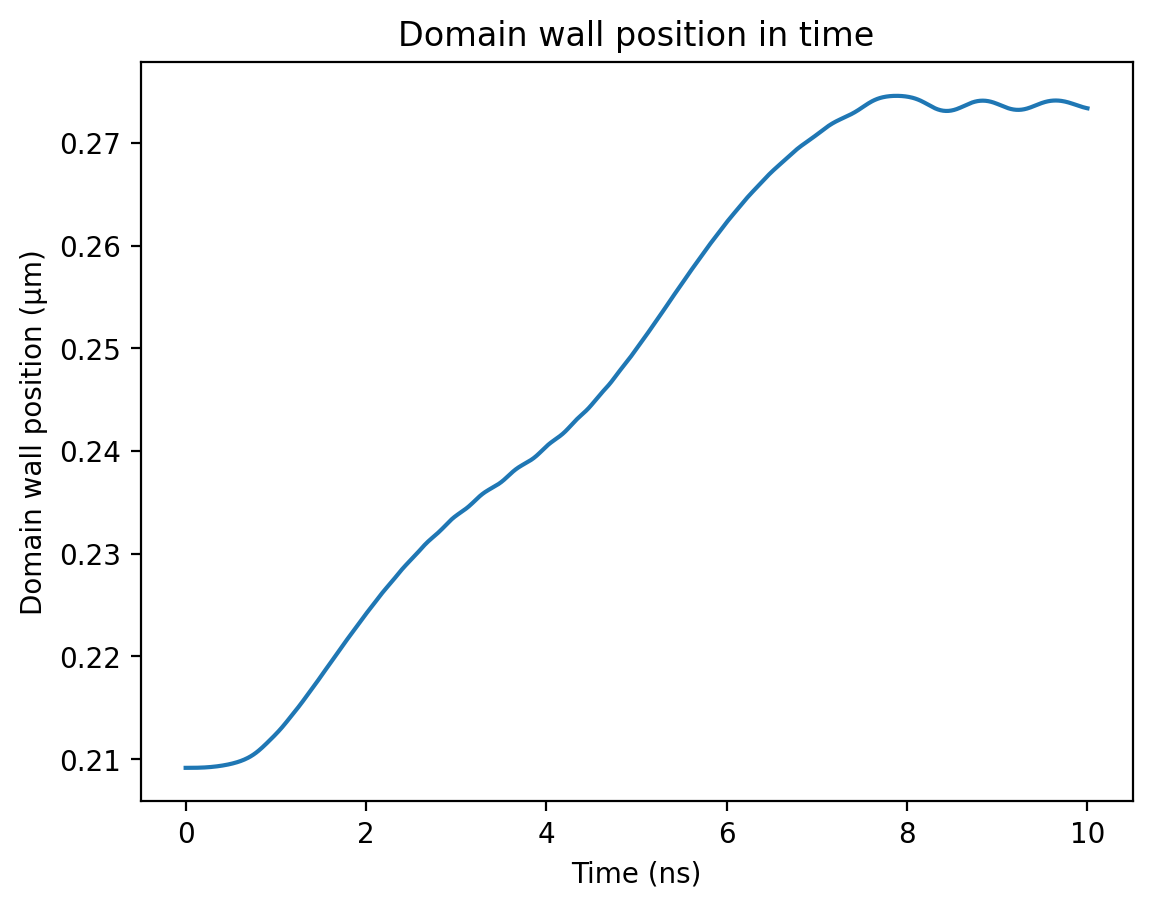

In [3]:
"""In this example we move a domain wall by setting a time and space dependent
   strain in a ferromagnet to simulate the effect of a SAW wave. This is
   based on the method used in
   https://journals.aps.org/prb/abstract/10.1103/PhysRevB.108.104420."""

import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import plot_field, twodomain

plt.rcParams['figure.dpi'] = 200

# simulation time
run = 10e-9
steps = 1000
dt = run/steps

# simulation grid parameters
# Use a very large y cell size and periodic boundary conditions to replicate a
# wider track while only simulating a thin strip
nx, ny, nz = 256, 8, 1
cx, cy, cz = 2.4e-9, 4 * 2.4e-9, 1e-9
mastergrid, pbc_repetitions = Grid((0, ny, 0)), (0, 4, 0)

# create a world and a magnet
cellsize = (cx, cy, cz)
world = World(cellsize, mastergrid=mastergrid, pbc_repetitions=pbc_repetitions)
magnet = Ferromagnet(world, Grid((nx, ny, nz)))

# setting magnet parameters
magnet.msat = 6e5
magnet.aex = 1e-11
magnet.alpha = 0.01
magnet.ku1 = 8e5
magnet.anisU = (0,0,1)

# setting DMI to stabilize the DW
magnet.dmi_tensor.set_interfacial_dmi(1e-3)

# Create a DW
magnet.magnetization = twodomain((0,0,1), (-1,0,0), (0,0,-1), nx*cx/3, 5*cx)

print("minimizing...")
magnet.minimize()  # minimize

# magnetoelastic coupling constants
magnet.B1 = -1.5e7
magnet.B2 = 0

# amplitude, angular frequency and wave vector of the strain
E = 6e-3
w = 200e6 * 2*np.pi
k = 4000 / w

# normal stain, given by exx = E [sin(wt)*cos(kx) - cos(wt)*sin(kx)]
# Create the first time term
magnet.rigid_norm_strain.add_time_term(lambda t: (np.sin(w*t), 0., 0.),
                                       lambda x,y,z: (E*np.cos(k*x), 0., 0.))
# Add the second time term
magnet.rigid_norm_strain.add_time_term(lambda t: (np.cos(w*t), 0., 0.),
                                       lambda x,y,z: (-E*np.sin(k*x), 0., 0.))

# plot the initial and final magnetization
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, sharex="all", sharey="all")
plot_field(magnet.magnetization, ax=ax1, title="Initial magnetization",
           xlabel="", show=False, enable_quiver=False)

# function to estimate the position of the DW
def DW_position(magnet):
    m_av = magnet.magnetization.average()[2]
    return m_av*nx*cx / 2 + nx*cx/2

# run the simulation and save the DW postion
print("running...")
quantity_dict = {"DW_pos": lambda: DW_position(magnet)}
output = world.timesolver.solve(np.linspace(0, run, steps+1), quantity_dict, tqdm=True)
print("done!")

# final magnetization
plot_field(magnet.magnetization, ax=ax2, title="Final magnetization", show=True,
           enable_quiver=False)

# plot DW position as a function of time
plt.plot(np.array(output["time"])*1e9, np.array(output["DW_pos"])*1e6)
plt.xlabel("Time (ns)")
plt.ylabel("Domain wall position (µm)")
plt.title("Domain wall position in time")
plt.show()